In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
df = pd.read_csv("train.csv")

### 1. VERİYİ TANIMLAMA VE YAPISAL İNCELEME

In [16]:
# Boyut bilgisi
print(f"Veri Seti Boyutu: {df.shape[0]} satır, {df.shape[1]} sütun\n")

# Değişken isimleri
print(df.columns.tolist())

# Veri tipleri
df.info()
# İstatistiksel özet
display(df.describe().round(2).T)
# İlk 5 satır
display(df.head())

Veri Seti Boyutu: 891 satır, 12 sütun

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2. EKSİK VE AYKIRI DEĞER ANALİZİ

In [17]:
eksik_sayi = df.isnull().sum()
eksik_yuzde = (df.isnull().sum() / len(df) * 100).round(2)
eksik_df = pd.DataFrame({
    'Eksik Sayı': eksik_sayi,
    'Eksik Yüzde (%)': eksik_yuzde,
    'Veri Tipi': df.dtypes
})
eksik_df = eksik_df[eksik_df['Eksik Sayı'] > 0].sort_values('Eksik Sayı', ascending=False)
print('EKSİK VERİ RAPORU')
print('=' * 50)
print(eksik_df.to_string())

EKSİK VERİ RAPORU
          Eksik Sayı  Eksik Yüzde (%) Veri Tipi
Cabin            687            77.10       str
Age              177            19.87   float64
Embarked           2             0.22       str


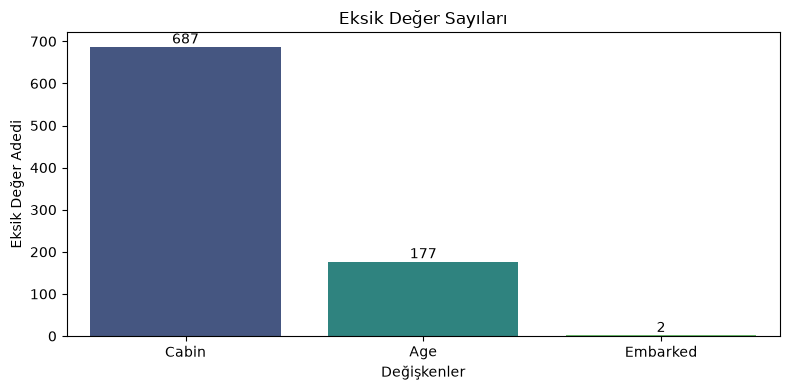

In [18]:
plt.figure(figsize=(8, 4))

# Bar Plot 
ax = sns.barplot(
    x=eksik_df.index, 
    y=eksik_df.iloc[:, 0], 
    hue=eksik_df.index, 
    palette='viridis', 
    legend=False
)

plt.title('Eksik Değer Sayıları')
plt.xlabel('Değişkenler')
plt.ylabel('Eksik Değer Adedi')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height), 
            ha='center', va='center', xytext=(0, 5), textcoords='offset points'
        )

plt.tight_layout()
plt.show()

Fare Değişkeni İstatistikleri:
-----------------------------
Q1 (%25 Çeyreklik) : 7.91
Q3 (%75 Çeyreklik) : 31.00
IQR                : 23.09
Hesaplanan Üst Sınır: 65.63
Aykırı Değer Sayısı: 116 (Toplam verinin %13.02'i)



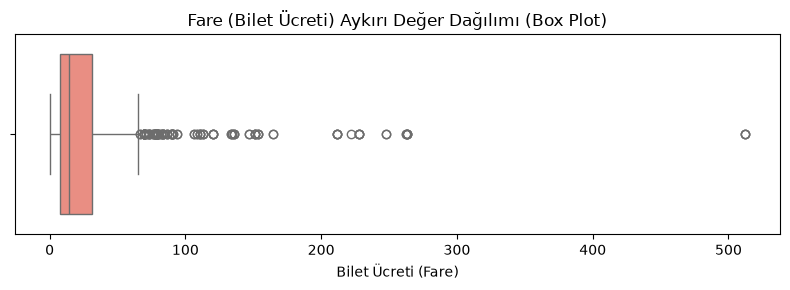

In [19]:
# Fare değişkeni için IQR yöntemiyle alt ve üst sınırların hesaplanması
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)
IQR = Q3 - Q1

alt_sınır = Q1 - 1.5 * IQR
ust_sınır = Q3 + 1.5 * IQR
outliers = df[(df['Fare'] < alt_sınır) | (df['Fare'] > ust_sınır)]
print(f"Fare Değişkeni İstatistikleri:")
print(f"-----------------------------")
print(f"Q1 (%25 Çeyreklik) : {Q1:.2f}")
print(f"Q3 (%75 Çeyreklik) : {Q3:.2f}")
print(f"IQR                : {IQR:.2f}")
print(f"Hesaplanan Üst Sınır: {ust_sınır:.2f}")
print(f"Aykırı Değer Sayısı: {len(outliers)} (Toplam verinin %{(len(outliers)/len(df))*100:.2f}'i)\n")


plt.figure(figsize=(8, 3))
sns.boxplot(x=df['Fare'], color='salmon')
plt.title('Fare (Bilet Ücreti) Aykırı Değer Dağılımı (Box Plot)')
plt.xlabel('Bilet Ücreti (Fare)')
plt.tight_layout()
plt.show()


### TEK DEĞİŞKENLİ ANALİZ

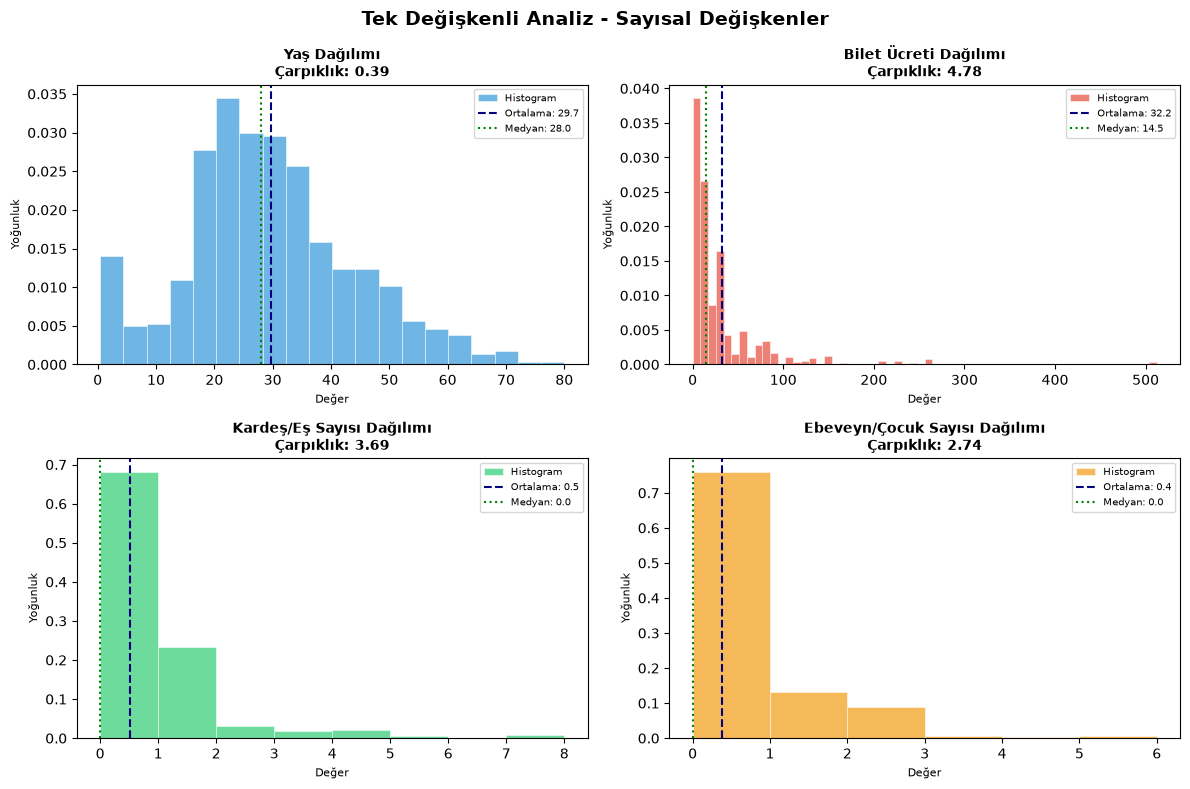

In [20]:
from scipy.stats import skew

# Analiz edilecek sayısal değişkenler
analiz_sutunlari_sayisal = [
    ('Age', '#3498db', 'Yaş Dağılımı'),
    ('Fare', '#e74c3c', 'Bilet Ücreti Dağılımı'),
    ('SibSp', '#2ecc71', 'Kardeş/Eş Sayısı Dağılımı'),
    ('Parch', '#f39c12', 'Ebeveyn/Çocuk Sayısı Dağılımı')
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Tek Değişkenli Analiz - Sayısal Değişkenler', fontsize=14, fontweight='bold')


axes_düz = axes.flatten()

for i, (col_name, renk, baslik) in enumerate(analiz_sutunlari_sayisal):
    ax = axes_düz[i]
    
    # Eksik değerleri at
    veri = df[col_name].dropna()
    
    # Histogram
    ax.hist(veri, bins='auto', color=renk, alpha=0.7, 
            density=True, edgecolor='white', linewidth=0.5,
            label='Histogram')
    
    # KDE
    try:
        kde_x = np.linspace(veri.min(), veri.max(), 200)
        kde = stats.gaussian_kde(veri)
        ax.plot(kde_x, kde(kde_x), color='darkred', linewidth=2, label='KDE')
    except:
        pass
    
    # Ortalama ve Medyan
    ax.axvline(veri.mean(), color='navy', linestyle='--', 
               linewidth=1.5, label=f'Ortalama: {veri.mean():.1f}')
    ax.axvline(veri.median(), color='green', linestyle=':', 
               linewidth=1.5, label=f'Medyan: {veri.median():.1f}')
    
    carpiklik = skew(veri)
    ax.set_title(f'{baslik}\nÇarpıklık: {carpiklik:.2f}', fontsize=10, fontweight='bold')
    ax.legend(fontsize=7, loc='upper right')
    ax.set_xlabel('Değer', fontsize=8)
    ax.set_ylabel('Yoğunluk', fontsize=8)

plt.tight_layout()
plt.show()

### KATEGORİK DEĞİŞKENLERİN TEK DEĞİŞKENLİ ANALİZİ

C:\Users\Asus\AppData\Local\Temp\ipykernel_4548\1251661126.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


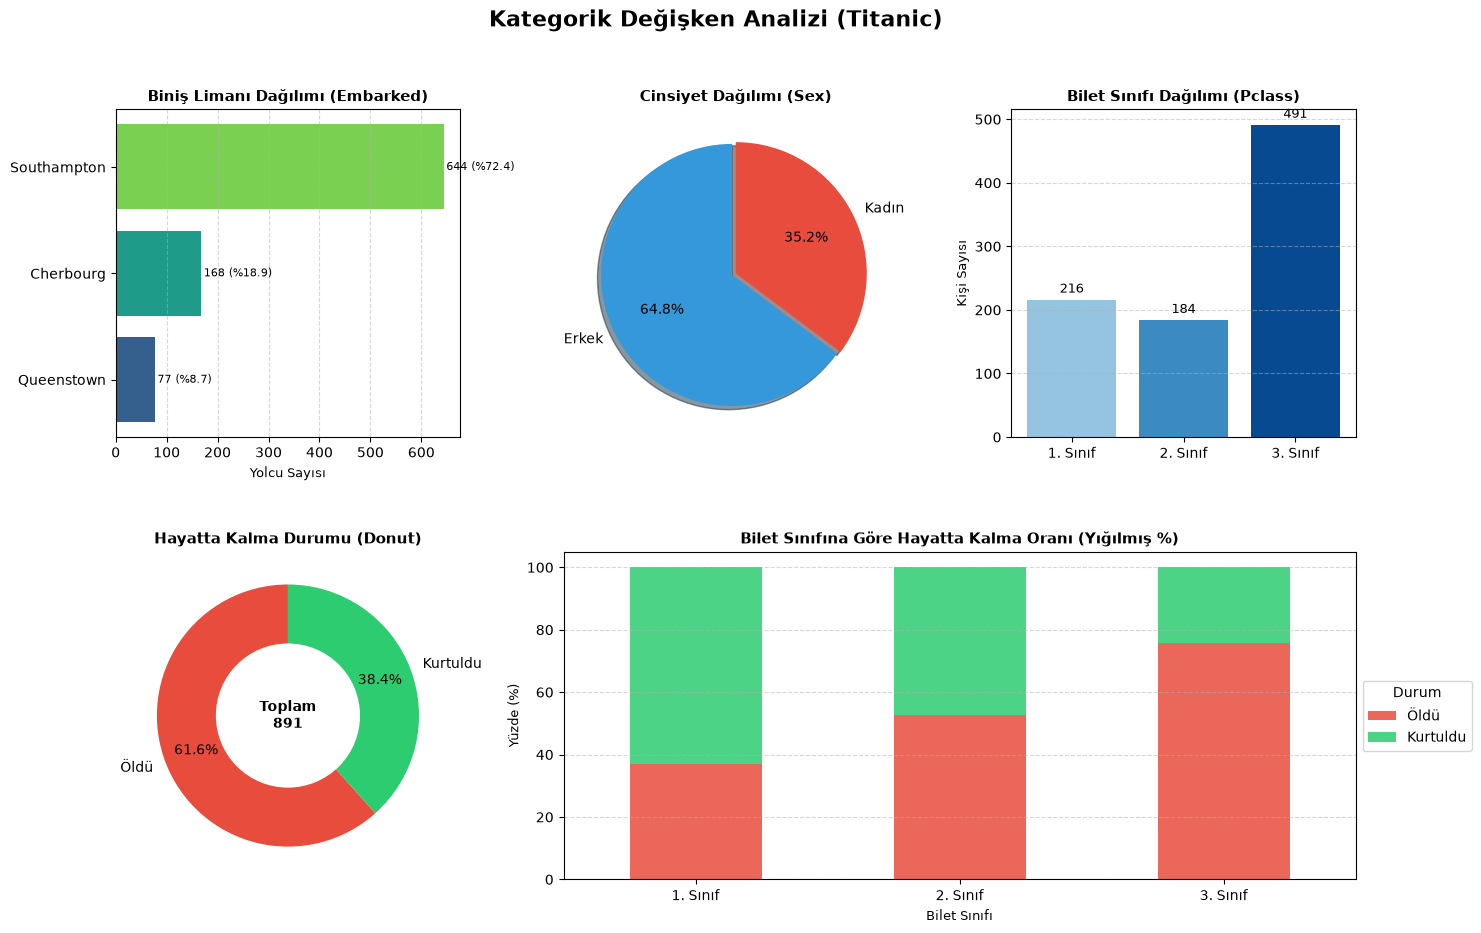

In [21]:

fig = plt.figure(figsize=(16, 10))
fig.suptitle('Kategorik Değişken Analizi (Titanic)', fontsize=16, fontweight='bold')
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)

# ----------------------------------------------------
# 1. Yatay Bar Chart
ax1 = fig.add_subplot(gs[0, 0])
emb_map = {'S': 'Southampton', 'C': 'Cherbourg', 'Q': 'Queenstown'}
emb_counts = df['Embarked'].map(emb_map).value_counts().sort_values()
colors_emb = plt.cm.viridis(np.linspace(0.3, 0.8, len(emb_counts)))

bars = ax1.barh(emb_counts.index, emb_counts.values, color=colors_emb)
ax1.set_title('Biniş Limanı Dağılımı (Embarked)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Yolcu Sayısı', fontsize=9)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# Barların sağ ucuna değer ve yüzde yazma
total_emb = emb_counts.sum()
for bar in bars:
    width = bar.get_width()
    pct = (width / total_emb) * 100
    ax1.text(width + 5, bar.get_y() + bar.get_height()/2, f'{int(width)} (%{pct:.1f})', 
             va='center', fontsize=8)


# 2. Cinsiyet Dağılımı
ax2 = fig.add_subplot(gs[0, 1])
sex_counts = df['Sex'].map({'female': 'Kadın', 'male': 'Erkek'}).value_counts()
colors_sex = ['#3498db', '#e74c3c']

ax2.pie(sex_counts, labels=sex_counts.index, autopct='%1.1f%%', startangle=90,
        colors=colors_sex, shadow=True, explode=(0.03, 0), textprops={'fontsize': 10})
ax2.set_title('Cinsiyet Dağılımı (Sex)', fontsize=11, fontweight='bold')


# 3. Bilet Sınıfı

ax3 = fig.add_subplot(gs[0, 2])
pclass_counts = df['Pclass'].map({1: '1. Sınıf', 2: '2. Sınıf', 3: '3. Sınıf'}).value_counts().sort_index()
colors_pclass = plt.cm.Blues(np.linspace(0.4, 0.9, len(pclass_counts)))

bars3 = ax3.bar(pclass_counts.index, pclass_counts.values, color=colors_pclass)
ax3.set_title('Bilet Sınıfı Dağılımı (Pclass)', fontsize=11, fontweight='bold')
ax3.set_ylabel('Kişi Sayısı', fontsize=9)
ax3.grid(axis='y', linestyle='--', alpha=0.5)

# Barların tepesine değer yazma
for bar in bars3:
    height = bar.get_height()
    ax3.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=9)


# 4. Hayatta Kalma 

ax4 = fig.add_subplot(gs[1, 0])
surv_counts = df['Survived'].map({0: 'Öldü', 1: 'Kurtuldu'}).value_counts()
colors_surv = ['#e74c3c', '#2ecc71']

wedges, texts, autotexts = ax4.pie(surv_counts, labels=surv_counts.index, autopct='%1.1f%%',
                                  startangle=90, colors=colors_surv, pctdistance=0.75)

# Donut deliği oluşturma
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
ax4.add_artist(centre_circle)

# halkanın ortasına toplam kişi sayısını yazma
ax4.text(0, 0, f'Toplam\n{len(df)}', ha='center', va='center', fontweight='bold', fontsize=10)
ax4.set_title('Hayatta Kalma Durumu (Donut)', fontsize=11, fontweight='bold')


# 5. Yığılmış Bar 

ax5 = fig.add_subplot(gs[1, 1:]) # Son iki sütunu kaplasın
ct = pd.crosstab(df['Pclass'], df['Survived'], normalize='index') * 100
ct.index = ['1. Sınıf', '2. Sınıf', '3. Sınıf']
ct.columns = ['Öldü', 'Kurtuldu']

ct.plot(kind='bar', stacked=True, ax=ax5, color=['#e74c3c', '#2ecc71'], alpha=0.85)
ax5.set_title('Bilet Sınıfına Göre Hayatta Kalma Oranı (Yığılmış %)', fontsize=11, fontweight='bold')
ax5.set_xlabel('Bilet Sınıfı', fontsize=9)
ax5.set_ylabel('Yüzde (%)', fontsize=9)
ax5.set_xticklabels(ct.index, rotation=0)
ax5.grid(axis='y', linestyle='--', alpha=0.5)
ax5.legend(title='Durum', loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

### ÇOK DEĞİŞKENLİ ANALİZ

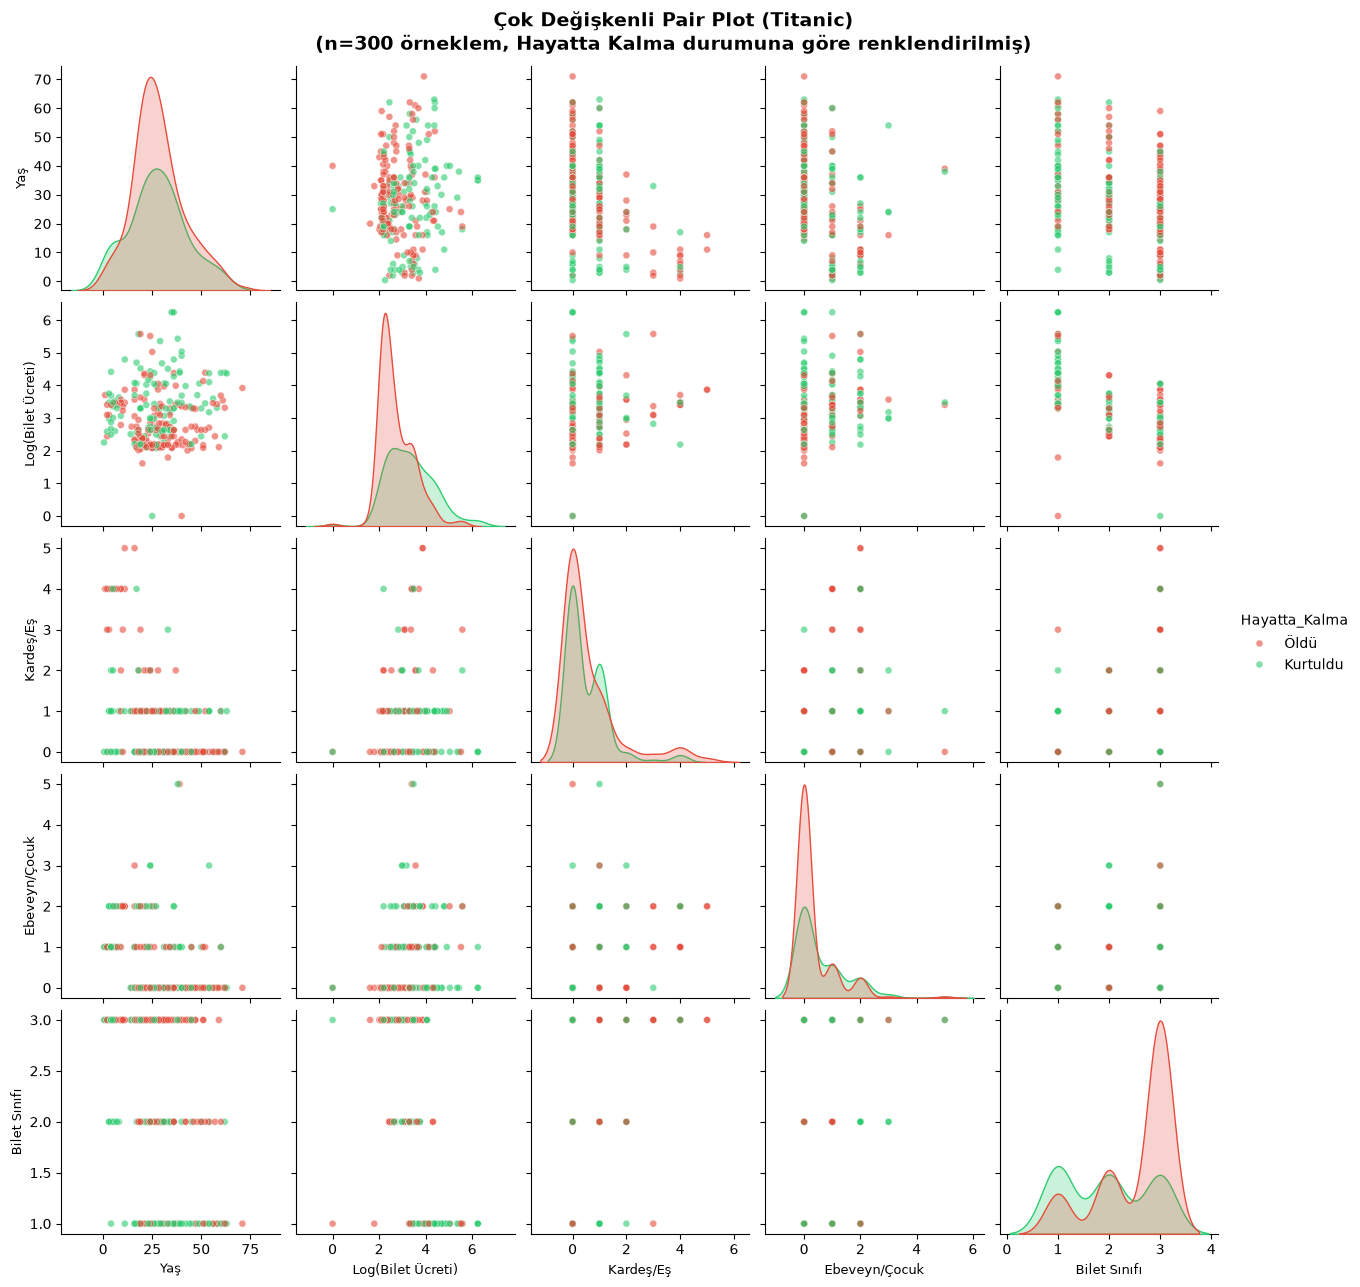

In [22]:
# ÇOK DEĞİŞKENLİ ANALİZ - PAIR PLOT (TITANIC)


sutunlar = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'Survived']
df_orneklem = df[sutunlar].dropna().copy()


if len(df_orneklem) > 300:
    df_orneklem = df_orneklem.sample(300, random_state=42)


df_orneklem['log_fare'] = np.log1p(df_orneklem['Fare'])


df_orneklem['Hayatta_Kalma'] = df_orneklem['Survived'].map({0: 'Öldü', 1: 'Kurtuldu'})

# Pair plot oluştur
g = sns.pairplot(
    df_orneklem[['Age', 'log_fare', 'SibSp', 'Parch', 'Pclass', 'Hayatta_Kalma']],
    hue='Hayatta_Kalma',      # Renk kodlaması: Hayatta Kalma durumuna göre
    diag_kind='kde',          # Diagonal: KDE yoğunluk grafiği
    plot_kws=dict(alpha=0.6, s=25),  # Saçılım noktaları ayarı
    diag_kws=dict(fill=True),        # KDE altını doldur
    palette={'Öldü': '#e74c3c', 'Kurtuldu': '#2ecc71'},
    corner=False              # Tam matris göster
)

g.figure.suptitle('Çok Değişkenli Pair Plot (Titanic)\n(n=300 örneklem, Hayatta Kalma durumuna göre renklendirilmiş)', 
                   y=1.03, fontsize=14, fontweight='bold')

# Eksen etiketlerini Türkçeleştir
etiket_map = {
    'Age': 'Yaş',
    'log_fare': 'Log(Bilet Ücreti)',
    'SibSp': 'Kardeş/Eş',
    'Parch': 'Ebeveyn/Çocuk',
    'Pclass': 'Bilet Sınıfı'
}

for ax in g.axes.flat:
    if ax:
        xlabel = ax.get_xlabel()
        ylabel = ax.get_ylabel()
        ax.set_xlabel(etiket_map.get(xlabel, xlabel), fontsize=9)
        ax.set_ylabel(etiket_map.get(ylabel, ylabel), fontsize=9)

plt.savefig('pair_plot_titanic.png', dpi=120, bbox_inches='tight')
plt.show()

### KORELASYON ANALİZİ

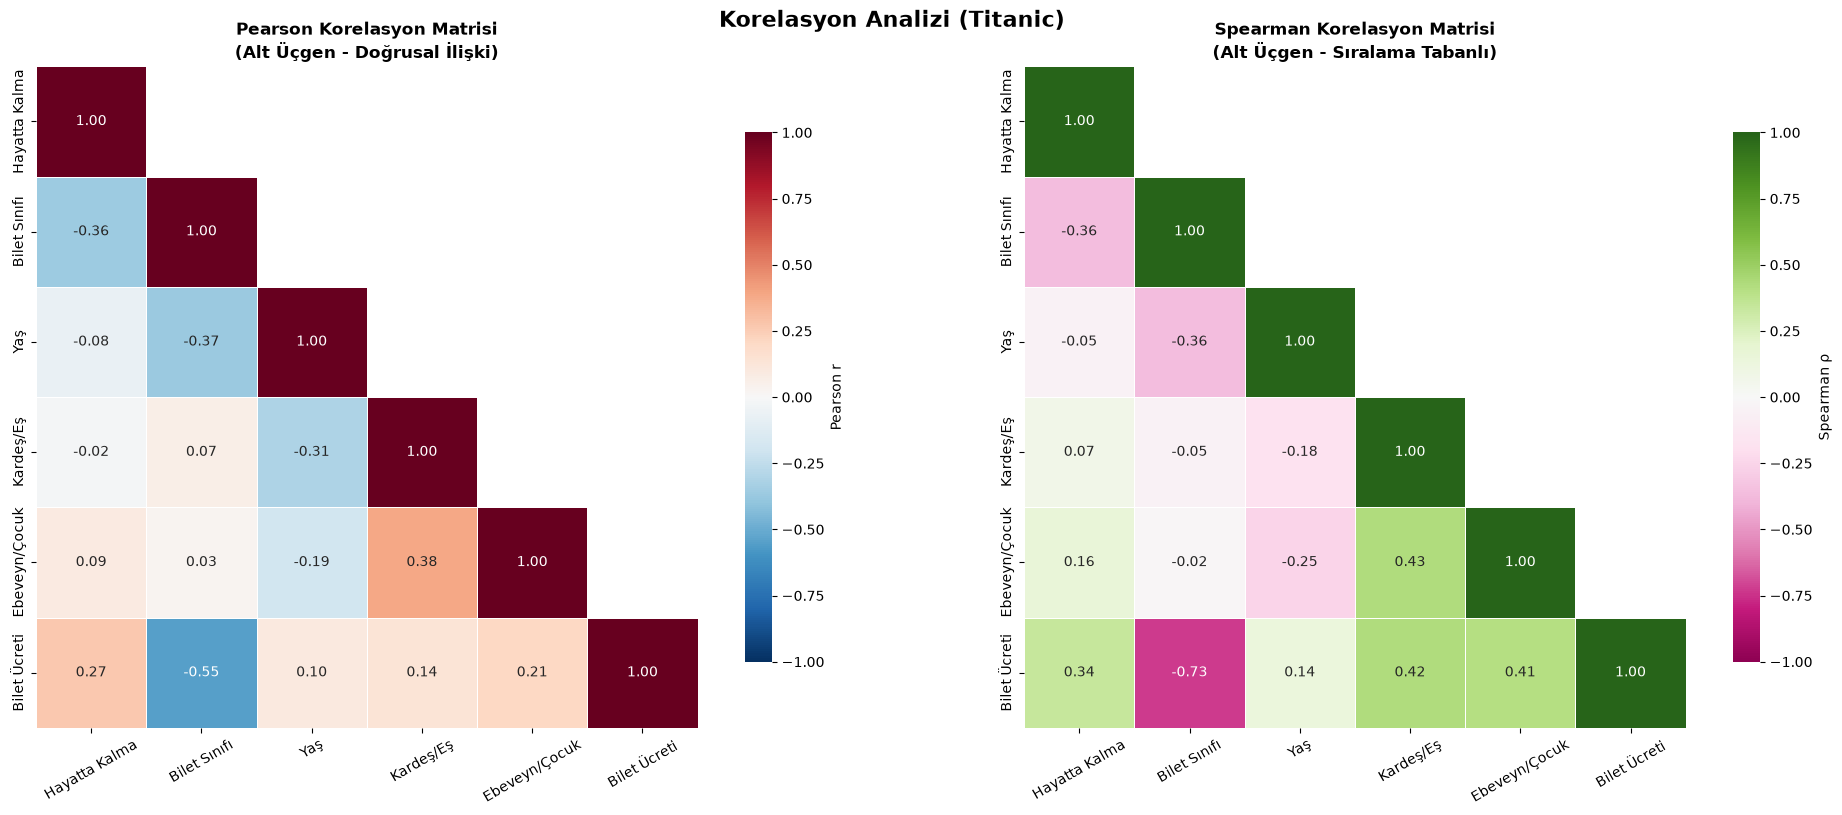


 EN YÜKSEK KORELASYONLAR (|r| > 0.1):
   Değişken 1    Değişken 2  Korelasyon
 Bilet Sınıfı  Bilet Ücreti   -0.554182
    Kardeş/Eş Ebeveyn/Çocuk    0.383820
 Bilet Sınıfı           Yaş   -0.369226
Hayatta Kalma  Bilet Sınıfı   -0.359653
          Yaş     Kardeş/Eş   -0.308247
Hayatta Kalma  Bilet Ücreti    0.268189
Ebeveyn/Çocuk  Bilet Ücreti    0.205119
          Yaş Ebeveyn/Çocuk   -0.189119
    Kardeş/Eş  Bilet Ücreti    0.138329


In [23]:
# KORELASYON ANALİZİ - TITANIC

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

fig.suptitle('Korelasyon Analizi (Titanic)', fontsize=16, fontweight='bold')

sayisal_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].dropna()

etiketler = ['Hayatta Kalma', 'Bilet Sınıfı', 'Yaş', 'Kardeş/Eş', 'Ebeveyn/Çocuk', 'Bilet Ücreti']

# Pearson
pearson_corr = sayisal_df.corr(method='pearson')
mask = np.triu(np.ones_like(pearson_corr, dtype=bool), k=1)

sns.heatmap(
    pearson_corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    xticklabels=etiketler,
    yticklabels=etiketler,
    ax=axes[0],
    cbar_kws={'label': 'Pearson r', 'shrink': 0.8}
)
axes[0].set_title('Pearson Korelasyon Matrisi\n(Alt Üçgen - Doğrusal İlişki)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

# Spearman
spearman_corr = sayisal_df.corr(method='spearman')
mask2 = np.triu(np.ones_like(spearman_corr, dtype=bool), k=1)

sns.heatmap(
    spearman_corr,
    mask=mask2,
    annot=True,
    fmt='.2f',
    cmap='PiYG',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    xticklabels=etiketler,
    yticklabels=etiketler,
    ax=axes[1],
    cbar_kws={'label': 'Spearman ρ', 'shrink': 0.8}
)
axes[1].set_title('Spearman Korelasyon Matrisi\n(Alt Üçgen - Sıralama Tabanlı)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('korelasyon_matrisi_titanic.png', dpi=150, bbox_inches='tight')
plt.show()

# En yüksek korelasyonlar
print('\n EN YÜKSEK KORELASYONLAR (|r| > 0.1):')

corr_pairs = pearson_corr.unstack().reset_index()
corr_pairs.columns = ['Değişken 1', 'Değişken 2', 'Korelasyon']

corr_pairs['abs_corr'] = corr_pairs['Korelasyon'].abs()
corr_pairs = corr_pairs[
    (corr_pairs['Değişken 1'] != corr_pairs['Değişken 2']) &
    (corr_pairs['abs_corr'] > 0.1)
]

corr_pairs['pair'] = corr_pairs.apply(lambda row: tuple(sorted([row['Değişken 1'], row['Değişken 2']])), axis=1)
corr_pairs = corr_pairs.drop_duplicates(subset=['pair']).sort_values('abs_corr', ascending=False)
corr_pairs = corr_pairs.drop(columns=['abs_corr', 'pair'])

isim_haritasi = dict(zip(sayisal_df.columns, etiketler))
corr_pairs['Değişken 1'] = corr_pairs['Değişken 1'].map(isim_haritasi)
corr_pairs['Değişken 2'] = corr_pairs['Değişken 2'].map(isim_haritasi)

print(corr_pairs.head(10).to_string(index=False))

In [25]:
# BÖLÜM 14: EDA ÖZET RAPORU - TITANIC


from scipy.stats import skew

print('=' * 65)
print('📊 TITANIC EDA ÖZET RAPORU')
print('=' * 65)

# Biniş limanı en yüksek olanı bulmak için mod alma
en_cok_liman = df['Embarked'].mode()[0]
liman_map = {'S': 'Southampton', 'C': 'Cherbourg', 'Q': 'Queenstown'}
en_cok_liman_adi = liman_map.get(en_cok_liman, en_cok_liman)

print(f'''
📌 VERİ SETİ ÖZELLİKLERİ
{'─' * 40}
  • Toplam yolcu sayısı  : {len(df):,}
  • Toplam değişken sayısı: {len(df.columns)}
  • Toplam eksik veri    : {df.isnull().sum().sum()} değer ({df.isnull().sum().sum()/df.size*100:.1f}%)
  • En çok eksik olan    : Cabin ({df['Cabin'].isnull().sum()} eksik), Age ({df['Age'].isnull().sum()} eksik)

📌 SAYISAL DEĞİŞKEN İSTATİSTİKLERİ
{'─' * 40}
  • Yaş Dağılımı         : Ort={df['Age'].mean():.1f}, Medyan={df['Age'].median():.1f}, Min={df['Age'].min()}, Max={df['Age'].max()}
  • Bilet Ücreti (Fare)  : Ort={df['Fare'].mean():.2f} $, Medyan={df['Fare'].median():.2f} $
  • Ort. Kardeş/Eş       : {df['SibSp'].mean():.2f}
  • Ort. Ebeveyn/Çocuk   : {df['Parch'].mean():.2f}

📌 KATEGORİK DEĞİŞKEN ÖZETLERİ & HAYATTA KALMA
{'─' * 40}
  • Genel Hayatta Kalma  : %{(df['Survived'].mean()*100):.1f} (Hayatta Kalan: {df['Survived'].sum()}, Hayatını Kaybeden: {(df['Survived']==0).sum()})
  • Cinsiyet Dağılımı    : Erkek %{(df['Sex']=='male').mean()*100:.1f} / Kadın %{(df['Sex']=='female').mean()*100:.1f}
  • Kadın Hayatta Kalma  : %{(df[df['Sex']=='female']['Survived'].mean()*100):.1f}
  • Erkek Hayatta Kalma  : %{(df[df['Sex']=='male']['Survived'].mean()*100):.1f}
  • Baskın Sınıf         : 3. Sınıf (%{(df['Pclass']==3).mean()*100:.1f})
  • Yoğun Biniş Limanı   : {en_cok_liman_adi} (%{(df['Embarked']==en_cok_liman).mean()*100:.1f})

📌 AYKIRI DEĞER VE DAĞILIM DURUMU
{'─' * 40}
  • Bilet Ücretinde {((df['Fare'] > df['Fare'].quantile(0.99)).sum())} adet %99 üzeri aşırı aykırı değer
  • Bilet Ücreti Çarpıklık: carpıklık = {skew(df['Fare'].dropna()):.2f} (Aşırı Sağa Çarpık)
  • Yaş Çarpıklığı        : carpıklık = {skew(df['Age'].dropna()):.2f} (Hafif Sağa Çarpık)

📌 ÖNEMLİ BULGULAR
{'─' * 40}
  1. Cinsiyet, hayatta kalmadaki en belirleyici faktördür (Kadınlarda %74, Erkeklerde %19).
  2. Sosyoekonomik statü şansı doğrudan etkilemiştir (1. Sınıf %63, 3. Sınıf %24 hayatta kalma).
  3. Bilet Ücreti (Fare) ile Pclass arasında güçlü negatif korelasyon mevcuttur (r ≈ -0.55).
  4. Çocuk yaş grubunda (0-10 yaş) hayatta kalma oranı diğer yaş gruplarına göre daha yüksektir.
  5. Kalabalık ailelerde (SibSp + Parch > 3) hayatta kalma oranı belirgin şekilde düşmektedir.

📌 SONRAKİ ADIMLAR VE ÖNERİLER (FEATURE ENGINEERING & MODELING)
{'─' * 40}
  → Eksik Değerler: 'Age' için Title/Pclass gruplamalı medyan doldurma, 'Embarked' için mod doldurma.
  → Yeni Değişkenler: 'FamilySize' (SibSp + Parch + 1) ve 'IsAlone' değişkenleri türetilmeli.
  → İsimden Unvan Çıkarma: 'Name' sütunundan 'Title' (Mr, Mrs, Miss, Master) değişkeni elde edilmeli.
  → Dönüşümler: 'Fare' değişkenindeki yüksek çarpıklık için Log Transformation (np.log1p) uygulanmalı.
  → Kodlama: 'Sex' ve 'Embarked' için One-Hot Encoding uygulanmalı.
''')

print('=' * 65)
print('✅ EDA Özet Raporu Başarıyla Oluşturuldu!')
print('=' * 65)

📊 TITANIC EDA ÖZET RAPORU

📌 VERİ SETİ ÖZELLİKLERİ
────────────────────────────────────────
  • Toplam yolcu sayısı  : 891
  • Toplam değişken sayısı: 12
  • Toplam eksik veri    : 866 değer (8.1%)
  • En çok eksik olan    : Cabin (687 eksik), Age (177 eksik)

📌 SAYISAL DEĞİŞKEN İSTATİSTİKLERİ
────────────────────────────────────────
  • Yaş Dağılımı         : Ort=29.7, Medyan=28.0, Min=0.42, Max=80.0
  • Bilet Ücreti (Fare)  : Ort=32.20 $, Medyan=14.45 $
  • Ort. Kardeş/Eş       : 0.52
  • Ort. Ebeveyn/Çocuk   : 0.38

📌 KATEGORİK DEĞİŞKEN ÖZETLERİ & HAYATTA KALMA
────────────────────────────────────────
  • Genel Hayatta Kalma  : %38.4 (Hayatta Kalan: 342, Hayatını Kaybeden: 549)
  • Cinsiyet Dağılımı    : Erkek %64.8 / Kadın %35.2
  • Kadın Hayatta Kalma  : %74.2
  • Erkek Hayatta Kalma  : %18.9
  • Baskın Sınıf         : 3. Sınıf (%55.1)
  • Yoğun Biniş Limanı   : Southampton (%72.3)

📌 AYKIRI DEĞER VE DAĞILIM DURUMU
────────────────────────────────────────
  • Bilet Ücretinde 9 ade